# EDA dữ liệu recommendation

## Phạm vi và nguyên tắc

Khảo sát hai nguồn tương tác: Gold hiện tại đã qua ETL và log lịch sử còn thô,
cùng metadata video từ cả hai nguồn. Dữ liệu hành vi là giả lập; metadata được crawl.
Raw hiện tại dùng đối chiếu provenance, không cộng lần nữa như sự kiện mới của Gold.

EDA không sửa Bronze/Silver/Gold, không thay user_id gốc, không loại sự kiện,
không điền giá trị thiếu, không tạo nhãn học, không chia tập và không train.
Các lát cắt, cờ và phép nối dưới đây chỉ là bảng tạm phục vụ phân tích.
Đầu vào gốc được kiểm tra fingerprint trước/sau; đầu ra chỉ là bảng/biểu đồ mô tả.

## 1. Nguồn dữ liệu và tính toàn vẹn


In [2]:
import json
from pathlib import Path

import pandas as pd


working_directory = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        directory
        for directory in [
            working_directory,
            *working_directory.parents,
        ]
        if (directory / "recommendation" / "config.json").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Không xác định được thư mục dự án")

REPORT_DIR = PROJECT_ROOT / "recommendation" / "reports"

inventory = json.loads(
    (REPORT_DIR / "source_inventory_v1.json").read_text(
        encoding="utf-8"
    )
)

gold_provenance = json.loads(
    (REPORT_DIR / "gold_provenance_v1.json").read_text(
        encoding="utf-8"
    )
)

source_overview = pd.DataFrame([
    {
        "Nguồn tương tác": "Hiện tại — Gold",
        "Số sự kiện": gold_provenance["gold_event_count"],
        "Trạng thái": "Đã qua ETL; xác định được run nguồn",
    },
    {
        "Nguồn tương tác": "Lịch sử collaborator",
        "Số sự kiện": inventory["historical_interactions"]["event_count"],
        "Trạng thái": "Còn thô; ranh giới lần sinh user chưa xác minh",
    },
])

print(
    "Tổng video khác nhau:",
    inventory["catalogue"]["union_count"],
)

display(source_overview)

Tổng video khác nhau: 560


,Nguồn tương tác,Số sự kiện,Trạng thái
0,Hiện tại — Gold,28762,Đã qua ETL; xác định được run nguồn
1,Lịch sử collaborator,30796,Còn thô; ranh giới lần sinh user chưa xác minh


In [3]:
import subprocess
import sys

source_directory = PROJECT_ROOT / "recommendation/src"
if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))
from pipeline_common import ARTIFACTS, snapshot_sources

snapshot_sources()
source_path = ARTIFACTS / "sources/gold.jsonl"
gold_records = [
    {key:value for key,value in json.loads(line).items() if key != "cohort"}
    for line in source_path.read_text(encoding="utf-8").splitlines() if line.strip()
]
gold_interactions = pd.DataFrame(gold_records)
if len(gold_interactions) != gold_provenance["gold_event_count"]:
    raise ValueError("Số sự kiện Gold không khớp provenance")
print("Nguồn: snapshot Gold đã xác minh; không truy vấn lại DB")
print("Gold:", gold_interactions.shape)


Nguồn: snapshot Gold đã xác minh; không truy vấn lại DB
Gold: (28762, 22)


In [4]:
import io
import tarfile

from inspect_sources import parse_jsonl


configuration = json.loads(
    (PROJECT_ROOT / "recommendation" / "config.json").read_text(
        encoding="utf-8"
    )
)

historical_commit = inventory["historical_commit"]
historical_directory = (
    configuration["sources"]["historical_root"]
    + "/user_interaction_logs"
)

archive_result = subprocess.run(
    [
        "git", "archive",
        historical_commit,
        historical_directory,
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    check=True,
)

historical_records = []
historical_source_files = []

with tarfile.open(
    fileobj=io.BytesIO(archive_result.stdout),
    mode="r:",
) as archive:
    for member in archive:
        if not member.isfile() or not member.name.endswith(".jsonl"):
            continue

        with archive.extractfile(member) as file:
            text = file.read().decode("utf-8-sig")

        for _, record in parse_jsonl(text, member.name):
            historical_records.append(record)
            historical_source_files.append(member.name)

historical_interactions = pd.DataFrame(historical_records)

if "_source_file" in historical_interactions.columns:
    raise ValueError("Tên cột provenance đã có trong dữ liệu gốc")

historical_interactions["_source_file"] = historical_source_files

if len(historical_interactions) != inventory["historical_interactions"]["event_count"]:
    raise ValueError("Số sự kiện lịch sử không khớp báo cáo kiểm kê")

print("Lịch sử:", historical_interactions.shape)

Lịch sử: (30796, 20)


In [5]:
import hashlib
from inspect_sources import source_checksums, protected_file_checksums

def frame_fingerprint(frame):
    serialised = frame.to_json(
        orient="split", force_ascii=False, double_precision=15
    )
    return hashlib.sha256(serialised.encode("utf-8")).hexdigest()

inspection_manifest = json.loads(
    (REPORT_DIR / "source_manifest_v1.json").read_text(encoding="utf-8")
)
if source_checksums(configuration["sources"]) != inspection_manifest["source_file_sha256"]:
    raise ValueError("Nguồn đã đổi so với manifest; cần kiểm kê phiên bản mới")
protected_before_eda = protected_file_checksums()
if protected_before_eda != inspection_manifest["protected_file_sha256"]:
    raise ValueError("Code/cấu hình được bảo vệ đã đổi so với manifest")
gold_identity_records = [
    {name: record[name] for name in ["event_id", "user_id", "video_id"]}
    for record in gold_records
]
identity_hash = hashlib.sha256(json.dumps(
    gold_identity_records, ensure_ascii=False, sort_keys=True
).encode("utf-8")).hexdigest()
if identity_hash != gold_provenance["gold_snapshot_sha256"]:
    raise ValueError("Danh tính sự kiện Gold đổi so với báo cáo provenance")
input_fingerprints = {
    "gold": frame_fingerprint(gold_interactions),
    "historical": frame_fingerprint(historical_interactions),
}
print("Đầu vào khớp manifest.")


Đầu vào khớp manifest.


In [6]:
def summarise_columns(frame):
    empty_string_counts = frame.apply(
        lambda column: column.map(
            lambda value: (
                isinstance(value, str)
                and not value.strip()
            )
        ).sum()
    )

    return pd.DataFrame({
        "Kiểu dữ liệu": frame.dtypes.astype(str),
        "Số giá trị thiếu": frame.isna().sum(),
        "Tỷ lệ thiếu (%)": (
            frame.isna().mean() * 100
        ).round(2),
        "Số chuỗi rỗng": empty_string_counts,
        "Số giá trị khác nhau": frame.nunique(dropna=True),
    })


gold_column_summary = summarise_columns(gold_interactions)
historical_column_summary = summarise_columns(
    historical_interactions
)

print("Gold hiện tại")
display(gold_column_summary)

print("Tương tác lịch sử")
display(historical_column_summary)

Gold hiện tại


,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số chuỗi rỗng,Số giá trị khác nhau
event_id,str,0,0.0,0,28762
session_id,str,0,0.0,0,3949
user_id,str,0,0.0,0,100
video_id,str,0,0.0,0,107
event_type,str,0,0.0,0,1
impression_index,int64,0,0.0,0,30
watch_duration_seconds,float64,547,1.9,0,7636
completion_rate,float64,547,1.9,0,1232
comment_read_duration_seconds,float64,0,0.0,0,2102
click_profile,int64,0,0.0,0,2


Tương tác lịch sử


,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số chuỗi rỗng,Số giá trị khác nhau
event_id,str,0,0.00,0,30299
session_id,str,0,0.00,0,3827
user_id,str,519,1.69,0,1072
video_id,str,0,0.00,0,491
event_type,str,0,0.00,0,1
impression_index,int64,0,0.00,0,30
watch_duration_seconds,float64,489,1.59,0,8292
completion_rate,float64,993,3.22,0,1722
comment_read_duration_seconds,float64,0,0.00,0,2129
click_profile,int64,0,0.00,0,2


### Cấu trúc và giá trị thiếu

Gold có 28.762 sự kiện với event_id duy nhất và không thiếu user_id.
Hai trường watch/completion cùng thiếu 547 giá trị. Các kiểm tra tiếp theo
đối chiếu trực tiếp nguyên nhân thiếu thay vì mặc định điền bằng 0.

Lịch sử có 30.796 dòng, 30.299 event_id khác nhau, 519 dòng thiếu user_id.
Con số user_id trong bảng có cả bot; session_id lặp là bình thường khi
một phiên có nhiều sự kiện. Hai nguồn đang ở hai trạng thái xử lý khác nhau.


In [7]:
def summarise_watch_quality(frame):
    watch_duration = frame["watch_duration_seconds"]
    completion_rate = frame["completion_rate"]
    blocked = frame["action_block_creator"].eq(1)

    return pd.Series({
        "Thiếu thời gian xem": watch_duration.isna().sum(),
        "Thiếu completion": completion_rate.isna().sum(),
        "Thiếu cả hai": (
            watch_duration.isna()
            & completion_rate.isna()
        ).sum(),
        "Có thời gian xem nhưng thiếu completion": (
            watch_duration.notna()
            & completion_rate.isna()
        ).sum(),
        "Thiếu thời gian xem và có block": (
            watch_duration.isna() & blocked
        ).sum(),
        "Thiếu thời gian xem và không có block": (
            watch_duration.isna() & ~blocked
        ).sum(),
        "Thời gian xem âm": watch_duration.lt(0).sum(),
        "Thời gian xem vượt 3600 giây": (
            watch_duration.gt(3600).sum()
        ),
        "Completion âm": completion_rate.lt(0).sum(),
        "Completion lớn hơn 1": completion_rate.gt(1).sum(),
    })


watch_quality_summary = pd.DataFrame({
    "Gold": summarise_watch_quality(gold_interactions),
    "Lịch sử": summarise_watch_quality(
        historical_interactions
    ),
})

display(watch_quality_summary)

negative_watch = historical_interactions["watch_duration_seconds"].lt(0)
missing_completion_only = (
    historical_interactions["watch_duration_seconds"].notna()
    & historical_interactions["completion_rate"].isna()
)
negative_watch_matches_missing_completion = negative_watch.equals(missing_completion_only)
print("Nhóm thời gian xem âm trùng nhóm chỉ thiếu completion:",
      negative_watch_matches_missing_completion)


,Gold,Lịch sử
Thiếu thời gian xem,547,489
Thiếu completion,547,993
Thiếu cả hai,547,489
Có thời gian xem nhưng thiếu completion,0,504
Thiếu thời gian xem và có block,547,489
Thiếu thời gian xem và không có block,0,0
Thời gian xem âm,0,504
Thời gian xem vượt 3600 giây,0,491
Completion âm,0,0
Completion lớn hơn 1,14139,14674


Nhóm thời gian xem âm trùng nhóm chỉ thiếu completion: True


### Chất lượng thời gian xem

Toàn bộ watch time thiếu đi kèm completion thiếu và hành động block.
Giữ tín hiệu block để xem xét xây nhãn; không suy diễn watch thiếu là 0 giây.
Gold không có watch time âm hoặc vượt ngưỡng ETL 3.600 giây.

Lịch sử còn 504 dòng watch time âm và 491 dòng vượt 3.600 giây.
Đối chiếu mask xác nhận toàn bộ 504 dòng âm chính là nhóm còn watch time
nhưng thiếu completion; không phải hai nhóm lỗi độc lập.
Completion lớn hơn 1 không mặc nhiên là lỗi: có thể biểu diễn xem lại.


### Histogram: hình dạng phân phối

Mỗi cột biểu diễn số quan sát nằm trong một khoảng giá trị; hai nguồn dùng cùng
ranh giới khoảng để đối chiếu. Trục tung là số sự kiện, không phải xác suất thích.
Hai biểu đồ hàng trên giữ toàn bộ giá trị hữu hạn, dùng thang log cho số đếm
để nhìn thấy cả những khoảng có ít sự kiện. Hàng dưới phóng vùng 0–120 giây
và completion 0–2; số quan sát ngoài vùng được ghi ngay trên hình.
Các vùng phóng chỉ phục vụ quan sát, không loại dữ liệu đầu vào.


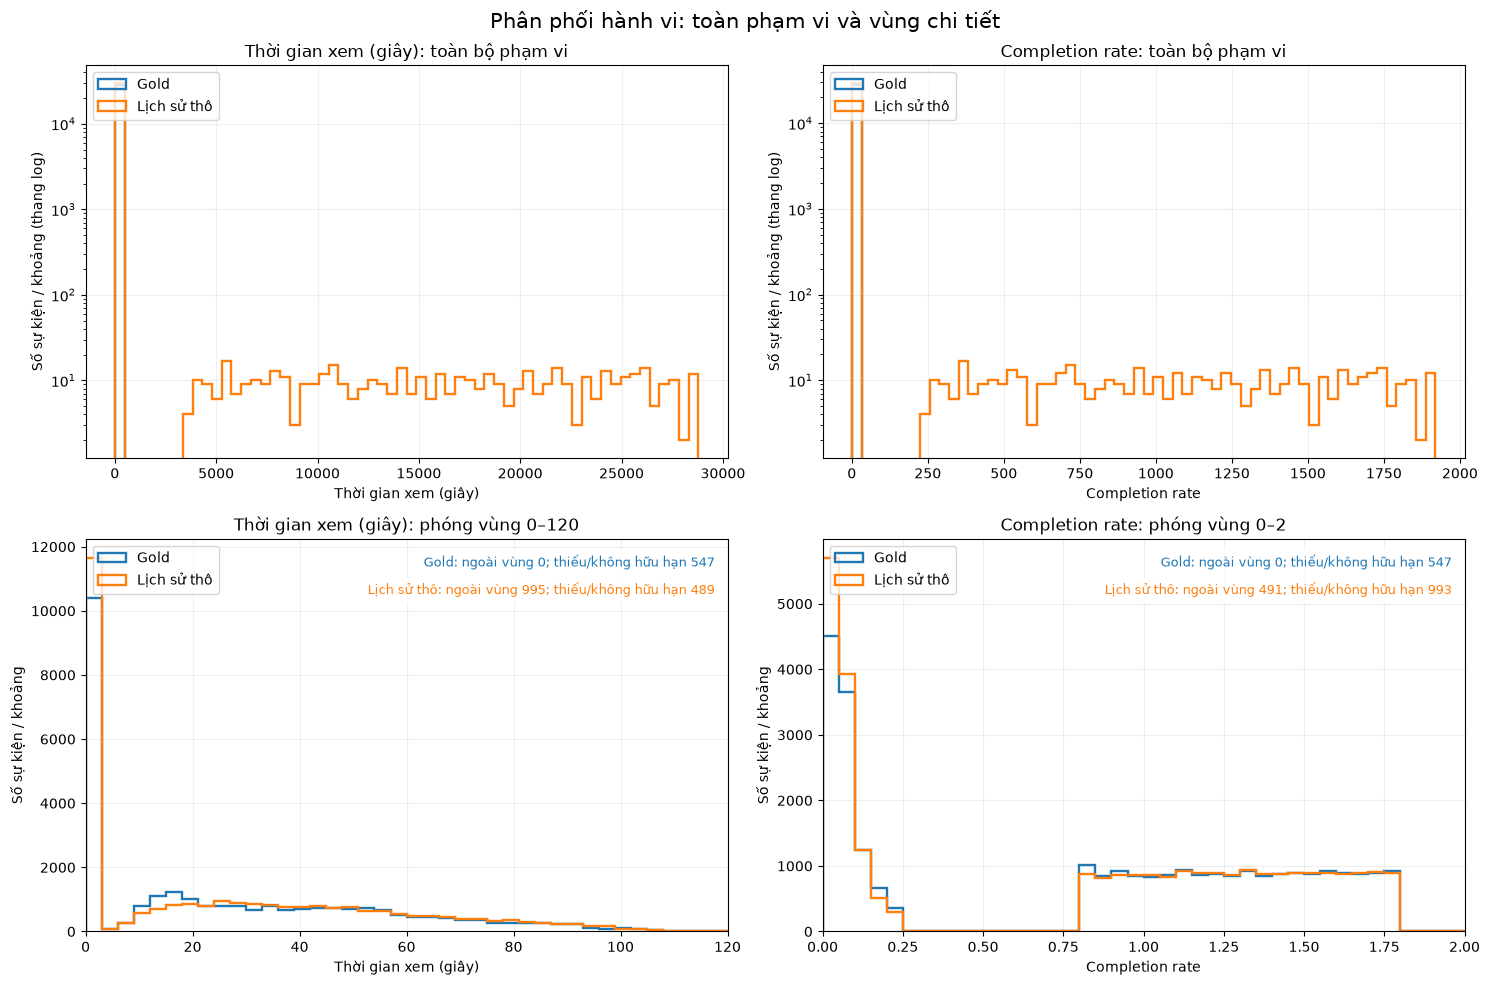

,Nguồn,Trường,Không có giá trị hữu hạn để vẽ,Ngoài vùng phóng,Giá trị nhỏ nhất,Giá trị lớn nhất
0,Gold,watch_duration_seconds,547,0,0.120,107.95
1,Lịch sử thô,watch_duration_seconds,489,995,-1.000,28787.54
2,Gold,completion_rate,547,0,0.020,1.80
3,Lịch sử thô,completion_rate,993,491,0.001,1919.17


In [8]:
import numpy as np
import matplotlib.pyplot as plt

def draw_behaviour_histograms():
    sources = {"Gold": gold_interactions, "Lịch sử thô": historical_interactions}
    colours = {"Gold": "tab:blue", "Lịch sử thô": "tab:orange"}
    settings = [
        ("watch_duration_seconds", "Thời gian xem (giây)", (0, 120)),
        ("completion_rate", "Completion rate", (0, 2)),
    ]
    figure, axes = plt.subplots(2, 2, figsize=(15, 10))
    histogram_rows = []
    for column_index, (column, label, window) in enumerate(settings):
        finite_values = {}
        for name, frame in sources.items():
            numeric = pd.to_numeric(frame[column], errors="coerce")
            finite_values[name] = numeric.loc[np.isfinite(numeric)].to_numpy()
        pooled = np.concatenate(list(finite_values.values()))
        full_bins = np.linspace(pooled.min(), pooled.max(), 61)
        detail_bins = np.linspace(*window, 41)
        for name, values in finite_values.items():
            axes[0, column_index].hist(
                values, bins=full_bins, histtype="step", linewidth=1.7,
                color=colours[name], label=name,
            )
            in_window = (values >= window[0]) & (values <= window[1])
            axes[1, column_index].hist(
                values[in_window], bins=detail_bins, histtype="step", linewidth=1.7,
                color=colours[name], label=name,
            )
            missing_count = len(sources[name]) - len(values)
            outside_count = int((~in_window).sum())
            histogram_rows.append({
                "Nguồn": name, "Trường": column,
                "Không có giá trị hữu hạn để vẽ": missing_count,
                "Ngoài vùng phóng": outside_count,
                "Giá trị nhỏ nhất": float(values.min()),
                "Giá trị lớn nhất": float(values.max()),
            })
            annotation = f"{name}: ngoài vùng {outside_count:,}; thiếu/không hữu hạn {missing_count:,}"
            axes[1, column_index].text(
                0.98, 0.96 if name == "Gold" else 0.89, annotation,
                transform=axes[1, column_index].transAxes, ha="right", va="top",
                fontsize=9, color=colours[name],
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
            )
        axes[0, column_index].set_yscale("log")
        axes[0, column_index].set_title(f"{label}: toàn bộ phạm vi")
        axes[0, column_index].set_ylabel("Số sự kiện / khoảng (thang log)")
        axes[1, column_index].set_xlim(*window)
        axes[1, column_index].set_title(f"{label}: phóng vùng {window[0]}–{window[1]}")
        axes[1, column_index].set_ylabel("Số sự kiện / khoảng")
        for axis in axes[:, column_index]:
            axis.set_xlabel(label)
            axis.grid(alpha=0.2)
            axis.legend(loc="upper left")
    figure.suptitle("Phân phối hành vi: toàn phạm vi và vùng chi tiết", fontsize=15)
    figure.tight_layout()
    plt.show()
    return pd.DataFrame(histogram_rows)

histogram_display_summary = draw_behaviour_histograms()
display(histogram_display_summary)


### Cách đọc histogram và giới hạn

Các cột cao ở vùng thời gian xem ngắn cho thấy nhiều sự kiện có thời gian xem thấp.
Completion không tạo một phân phối trơn duy nhất: cơ chế sinh hành vi dùng những
khoảng khác nhau cho phản hồi tích cực. Khoảng ít quan sát chưa chắc chứng
minh lỗi ở ETL, nó là đặc điểm thiết kế mô phỏng. Completion > 1 biểu diễn cả
khả năng xem lại, cần phân biệt với outlier đã đối chiếu ở phần chất lượng.

Ở toàn phạm vi, outlier lịch sử làm các giá trị thông thường dồn về các khoảng đầu.
Vùng phóng cho phép xem phần này rõ hơn mà vẫn công bố phần ngoài khung.
Số quan sát thiếu không được coi là bằng 0 và không xuất hiện thành cột tại 0.

Histogram hoạt động dùng chung ranh giới khoảng cho từng cột. Gold tách ba run,
không trộn các user ID giống tên thành một hồ sơ. Lịch sử user chỉ dùng lát cắt
không thiếu ID/không bot đã nêu. Bảng video lịch sử vẫn là log thô chứa bot và bản lặp.
Số video/user khác số sự kiện/user vì một video có thể được xem nhiều lần.
Đuôi phải của số sự kiện/video cho thấy một số ít video nhận nhiều sự kiện hơn.

In [9]:
def summarise_event_quality(frame):
    event_columns = [
        column
        for column in frame.columns
        if not column.startswith("_")
    ]

    bot_by_user_id = frame["user_id"].str.startswith(
        "bot_",
        na=False,
    )

    bot_by_app_version = frame["app_version"].eq(
        "bot_v1.0"
    )

    pair_variation = (
        frame.groupby("event_id")[["user_id", "video_id"]]
        .nunique(dropna=False)
    )

    return pd.Series({
        "Dòng trùng toàn bộ trường sự kiện": (
            frame.duplicated(subset=event_columns).sum()
        ),
        "Dòng lặp thêm theo event_id": (
            frame.duplicated(subset=["event_id"]).sum()
        ),
        "Event ID có nhiều dòng": (
            frame["event_id"].value_counts().gt(1).sum()
        ),
        "Event ID mâu thuẫn user hoặc video": (
            pair_variation.gt(1).any(axis=1).sum()
        ),
        "Sự kiện bot theo user ID": bot_by_user_id.sum(),
        "Sự kiện bot theo app_version": bot_by_app_version.sum(),
        "Sự kiện bot theo ít nhất một dấu hiệu": (
            bot_by_user_id | bot_by_app_version
        ).sum(),
    })


event_quality_summary = pd.DataFrame({
    "Gold": summarise_event_quality(gold_interactions),
    "Lịch sử": summarise_event_quality(
        historical_interactions
    ),
})

display(event_quality_summary)

,Gold,Lịch sử
Dòng trùng toàn bộ trường sự kiện,0,0
Dòng lặp thêm theo event_id,0,497
Event ID có nhiều dòng,0,497
Event ID mâu thuẫn user hoặc video,0,0
Sự kiện bot theo user ID,0,530
Sự kiện bot theo app_version,0,530
Sự kiện bot theo ít nhất một dấu hiệu,0,530


In [10]:
repeated_event_ids = (
    historical_interactions["event_id"]
    .value_counts()
    .loc[lambda counts: counts > 1]
    .head(3)
    .index
)

display(
    historical_interactions.loc[
        historical_interactions["event_id"].isin(
            repeated_event_ids
        ),
        [
            "event_id",
            "user_id",
            "video_id",
            "timestamp",
            "server_received_timestamp",
            "_source_file",
        ],
    ].sort_values(
        ["event_id", "server_received_timestamp"]
    )
)

,event_id,user_id,video_id,timestamp,server_received_timestamp,_source_file
140,evt_0f400ded99e4,usr_00227,K7JkYJgoQaE,1790822122000,1790822122026,raw/data_lake/raw/user_interaction_logs/year=2...
141,evt_0f400ded99e4,usr_00227,K7JkYJgoQaE,1790822122000,1790822122428,raw/data_lake/raw/user_interaction_logs/year=2...
20,evt_1a525dc43a27,usr_00242,JAUJPPMqogE,1790814956975,1790814957102,raw/data_lake/raw/user_interaction_logs/year=2...
21,evt_1a525dc43a27,usr_00242,JAUJPPMqogE,1790814956975,1790814957765,raw/data_lake/raw/user_interaction_logs/year=2...
23,evt_a71171088190,usr_00242,nV1Srns95nE,1790814975826,1790814975927,raw/data_lake/raw/user_interaction_logs/year=2...
24,evt_a71171088190,usr_00242,nV1Srns95nE,1790814975826,1790814976510,raw/data_lake/raw/user_interaction_logs/year=2...


### Sự kiện lặp và bot

Lịch sử có 497 event ID xuất hiện hai lần; không có mâu thuẫn user/video.
Phép kiểm tra toàn bộ trường ngay dưới đây xác nhận nội dung giống nhau
ngoài thời điểm server nhận và file nguồn. Đây là căn cứ đề xuất giữ
một bản theo event_id trong preprocessing, không phải xóa lượt xem lặp.

Hai dấu hiệu user_id bot và app_version xác định cùng 530 sự kiện.
Gold không còn các dạng lặp event ID hoặc dấu hiệu bot này.


In [11]:
repeated_rows = historical_interactions.loc[
    historical_interactions["event_id"].duplicated(
        keep=False
    )
]

comparison_columns = [
    column
    for column in historical_interactions.columns
    if column not in [
        "event_id",
        "server_received_timestamp",
        "_source_file",
    ]
]

repeated_event_variation = (
    repeated_rows
    .groupby("event_id")[comparison_columns]
    .nunique(dropna=False)
)

field_conflicts = (
    repeated_event_variation
    .gt(1)
    .sum()
    .rename("Số nhóm event ID có giá trị khác nhau")
    .to_frame()
)

display(field_conflicts)

print(
    "Số nhóm khác nội dung ngoài thời điểm nhận:",
    repeated_event_variation.gt(1).any(axis=1).sum(),
)

,Số nhóm event ID có giá trị khác nhau
session_id,0
user_id,0
video_id,0
event_type,0
impression_index,0
watch_duration_seconds,0
completion_rate,0
comment_read_duration_seconds,0
click_profile,0
action_like,0


Số nhóm khác nội dung ngoài thời điểm nhận: 0


In [12]:
from inspect_gold_provenance import collect_event_runs


interaction_directory = (
    PROJECT_ROOT
    / configuration["sources"]["current_root"]
    / "user_interaction_logs"
)

(
    event_runs,
    event_pairs,
    raw_file_checksums,
    raw_event_counts,
) = collect_event_runs(interaction_directory)

if raw_file_checksums != gold_provenance["source_file_sha256"]:
    raise ValueError(
        "Raw đã thay đổi so với báo cáo provenance; cần kiểm tra lại"
    )

matching_runs = gold_interactions["event_id"].map(
    lambda event_id: event_runs.get(event_id, set())
)

if not matching_runs.map(len).eq(1).all():
    raise ValueError(
        "Có sự kiện Gold không xác định được duy nhất một run"
    )

gold_eda = gold_interactions.assign(
    _source_run=matching_runs.map(
        lambda runs: next(iter(runs))
    )
)

run_summary = (
    gold_eda.groupby("_source_run")
    .agg(
        event_count=("event_id", "size"),
        user_id_count=("user_id", "nunique"),
        video_id_count=("video_id", "nunique"),
    )
    .rename(columns={
        "event_count": "Số sự kiện",
        "user_id_count": "Số user ID",
        "video_id_count": "Số video",
    })
)

display(run_summary)

scoped_user_count = (
    gold_eda.groupby(["_source_run", "user_id"]).ngroups
)

print(
    "Số danh tính user phân biệt theo run:",
    scoped_user_count,
)

,Số sự kiện,Số user ID,Số video
_source_run,,,
run=2ad86635f1a18e06,9631,100,76
run=94f1d592a7787780,9184,100,42
run=e1d06d3cf6587c44,9947,100,107


Số danh tính user phân biệt theo run: 300


### Phân biệt user theo lần sinh hồ sơ

Ba run hiện tại đều có 100 user ID nhưng khởi tạo hồ sơ riêng.
Vì vậy, phân tích hành vi phải sử dụng cặp (_source_run, user_id),
tương ứng 300 danh tính theo phạm vi lần chạy.

Số video có tương tác khác nhau giữa các run: 76, 42 và 107.
Đây là số video xuất hiện trong log, chưa tự chứng minh số video
có sẵn để đề xuất tại từng thời điểm.


In [13]:
user_activity = (
    gold_eda
    .groupby(["_source_run", "user_id"])
    .agg(
        event_count=("event_id", "size"),
        session_count=("session_id", "nunique"),
        distinct_video_count=("video_id", "nunique"),
    )
)

user_activity["repeat_event_count"] = (
    user_activity["event_count"]
    - user_activity["distinct_video_count"]
)

user_activity_summary = (
    user_activity
    .groupby(level="_source_run")
    .agg(
        minimum_events=("event_count", "min"),
        median_events=("event_count", "median"),
        maximum_events=("event_count", "max"),
        minimum_videos=("distinct_video_count", "min"),
        median_videos=("distinct_video_count", "median"),
        maximum_videos=("distinct_video_count", "max"),
    )
    .rename(columns={
        "minimum_events": "Sự kiện ít nhất/user",
        "median_events": "Trung vị sự kiện/user",
        "maximum_events": "Sự kiện nhiều nhất/user",
        "minimum_videos": "Video ít nhất/user",
        "median_videos": "Trung vị video/user",
        "maximum_videos": "Video nhiều nhất/user",
    })
)

display(user_activity_summary)

print("Ví dụ lịch sử của 5 danh tính:")
display(user_activity.head(5))

,Sự kiện ít nhất/user,Trung vị sự kiện/user,Sự kiện nhiều nhất/user,Video ít nhất/user,Trung vị video/user,Video nhiều nhất/user
_source_run,,,,,,
run=2ad86635f1a18e06,25,95.0,165,18,48.0,65
run=94f1d592a7787780,36,90.5,161,21,34.5,42
run=e1d06d3cf6587c44,34,97.5,175,27,59.5,88


Ví dụ lịch sử của 5 danh tính:


event_count  session_count  \
_source_run          user_id                                 
run=2ad86635f1a18e06 usr_00000          126             17   
                     usr_00001          114             14   
                     usr_00002           42              6   
                     usr_00003           69             12   
                     usr_00004           99             11   

                                distinct_video_count  repeat_event_count  
_source_run          user_id                                              
run=2ad86635f1a18e06 usr_00000                    58                  68  
                     usr_00001                    56                  58  
                     usr_00002                    30                  12  
                     usr_00003                    36                  33  
                     usr_00004                    51                  48

Lịch sử giữa các danh tính không đồng đều: số sự kiện dao động từ
25 đến 175; số video khác nhau dao động từ 18 đến 88.

Trung vị số video/user lần lượt là 48, 34,5 và 59,5 ở ba run.
Vì vậy, số sự kiện không thể dùng thay cho số cặp user–video khi
xác định lượng dữ liệu học và đánh giá.

Các lượt tương tác lặp với cùng video có thể là hành vi hợp lệ.
Cách tổng hợp chúng cần được quyết định trong preprocessing.

Lịch sử thực tế ngắn hơn pilot trước, nơi mỗi user được phân sẵn
210 video train. Chưa thể áp dụng lại cách chia và giao thức
đánh giá của pilot mà không kiểm tra điều kiện dữ liệu.

In [14]:
historical_bot_mask = (
    historical_interactions["user_id"].str.startswith(
        "bot_",
        na=False,
    )
    | historical_interactions["app_version"].eq("bot_v1.0")
)

historical_user_mask = (
    historical_interactions["user_id"].notna()
    & historical_interactions["user_id"].str.strip().ne("")
    & ~historical_bot_mask
)

historical_user_activity = (
    historical_interactions.loc[historical_user_mask]
    .groupby("user_id")
    .agg(
        event_count=("event_id", "size"),
        distinct_event_count=("event_id", "nunique"),
        session_count=("session_id", "nunique"),
        distinct_video_count=("video_id", "nunique"),
    )
)

print(
    "Số chuỗi user ID không phải bot:",
    len(historical_user_activity),
)

display(
    historical_user_activity.describe(
        percentiles=[0.25, 0.5, 0.75]
    ).T
)

Số chuỗi user ID không phải bot: 982


,count,mean,std,min,25%,50%,75%,max
event_count,982.0,30.292261,16.850761,2.0,18.0,28.0,41.0,99.0
distinct_event_count,982.0,29.786151,16.512038,2.0,17.0,27.0,40.0,98.0
session_count,982.0,3.897149,1.849763,1.0,2.0,4.0,5.0,10.0
distinct_video_count,982.0,28.110998,14.977145,2.0,17.0,26.0,38.0,83.0


### Nhận xét về lịch sử tương tác của các ID lịch sử

Có 982 chuỗi user ID không phải bot. Trung vị mỗi ID có 28 dòng
sự kiện, 27 event ID khác nhau, 4 phiên và 26 video khác nhau.

Độ dài lịch sử không đồng đều: số video khác nhau dao động từ
2 đến 83. Một số ID có rất ít dữ liệu, cần xem xét điều kiện
huấn luyện và đánh giá trong preprocessing.

Số liệu hiện vẫn bao gồm sự kiện lỗi và bản lặp; chưa phải
lượng dữ liệu cuối cùng dùng để học. Việc nhóm theo user_id
chỉ phục vụ khảo sát, chưa xác nhận tính liên tục của hồ sơ.


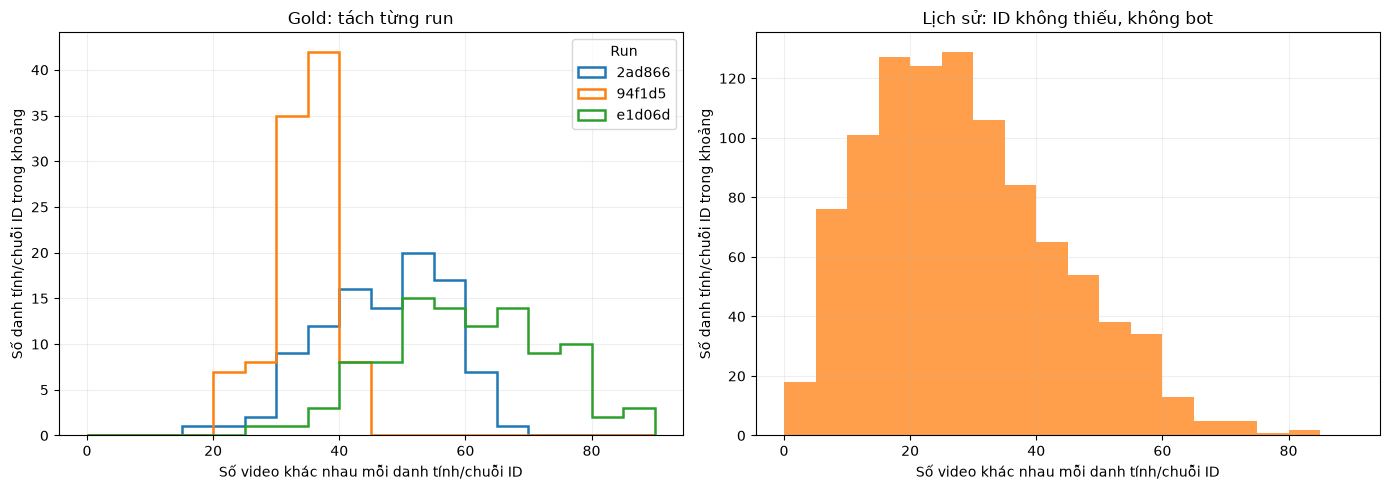

In [15]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
gold_user_series = {
    name.removeprefix("run=")[:6]: group["distinct_video_count"].to_numpy()
    for name, group in user_activity.groupby(level="_source_run")
}
user_bins = np.arange(0, max(
    max(values.max() for values in gold_user_series.values()),
    historical_user_activity["distinct_video_count"].max(),
) + 6, 5)
for label, values in gold_user_series.items():
    axes[0].hist(values, bins=user_bins, histtype="step", linewidth=1.8, label=label)
axes[1].hist(historical_user_activity["distinct_video_count"], bins=user_bins, color="tab:orange", alpha=0.75)
for axis, title in zip(axes, ["Gold: tách từng run", "Lịch sử: ID không thiếu, không bot"]):
    axis.set_title(title)
    axis.set_xlabel("Số video khác nhau mỗi danh tính/chuỗi ID")
    axis.set_ylabel("Số danh tính/chuỗi ID trong khoảng")
    axis.grid(alpha=0.2)
axes[0].legend(title="Run")
figure.tight_layout()
plt.show()


In [16]:
action_columns = [
    "click_profile",
    "action_like",
    "action_comment",
    "action_share",
    "action_skip",
    "action_block_creator",
]


def summarise_actions(frame):
    rows = []

    for column in action_columns:
        values = frame[column]

        rows.append({
            "Hành động": column,
            "Số giá trị 0": values.eq(0).sum(),
            "Số giá trị 1": values.eq(1).sum(),
            "Số giá trị thiếu": values.isna().sum(),
            "Số giá trị ngoài 0/1": (
                values.notna()
                & ~values.isin([0, 1])
            ).sum(),
            "Tỷ lệ 1 trên toàn bộ sự kiện (%)": (
                values.eq(1).sum() / len(frame) * 100
            ),
        })

    return pd.DataFrame(rows).set_index("Hành động")


print("Gold hiện tại")
display(summarise_actions(gold_eda).round(2))

print("Lịch sử thô, còn bot và bản lặp")
display(summarise_actions(historical_interactions).round(2))

Gold hiện tại


,Số giá trị 0,Số giá trị 1,Số giá trị thiếu,Số giá trị ngoài 0/1,Tỷ lệ 1 trên toàn bộ sự kiện (%)
Hành động,,,,,
click_profile,27048,1714,0,0,5.96
action_like,18487,10275,0,0,35.72
action_comment,27295,1467,0,0,5.10
action_share,27460,1302,0,0,4.53
action_skip,17781,10981,0,0,38.18
action_block_creator,28215,547,0,0,1.90


Lịch sử thô, còn bot và bản lặp


,Số giá trị 0,Số giá trị 1,Số giá trị thiếu,Số giá trị ngoài 0/1,Tỷ lệ 1 trên toàn bộ sự kiện (%)
Hành động,,,,,
click_profile,30019,777,0,0,2.52
action_like,20066,10730,0,0,34.84
action_comment,29218,1578,0,0,5.12
action_share,29435,1361,0,0,4.42
action_skip,18587,12209,0,0,39.64
action_block_creator,30307,489,0,0,1.59


Gold có tỷ lệ skip 38,18%, like 35,72% và block 1,90%.
Lịch sử thô có tỷ lệ skip 39,64%, like 34,84% và block 1,59%.

Tỷ lệ click_profile khác biệt rõ hơn: 5,96% ở Gold và 2,52%
ở lịch sử. Cần giữ thông tin nguồn khi phân tích, chưa kết luận
khác biệt này do chất lượng dữ liệu hay hành vi user.

Các tỷ lệ là thống kê trên sự kiện; không tương đương tỷ lệ user
có sở thích tích cực. Lịch sử vẫn chứa bot và bản lặp.
Chưa dùng riêng điều kiện không skip để xác định nhãn positive.

In [17]:
def summarise_response_patterns(frame):
    summary = (
        frame.groupby(
            ["action_skip", "action_block_creator"],
            dropna=False,
        )
        .agg(
            event_count=("event_id", "size"),
            like_count=("action_like", "sum"),
            share_count=("action_share", "sum"),
            missing_watch_count=(
                "watch_duration_seconds",
                lambda values: values.isna().sum(),
            ),
        )
    )

    summary["event_percentage"] = (
        summary["event_count"] / len(frame) * 100
    ).round(2)

    return summary.rename(columns={
        "event_count": "Số sự kiện",
        "like_count": "Có like",
        "share_count": "Có share",
        "missing_watch_count": "Thiếu thời gian xem",
        "event_percentage": "Tỷ lệ sự kiện (%)",
    })


print("Gold hiện tại")
display(summarise_response_patterns(gold_eda))

print("Lịch sử thô")
display(summarise_response_patterns(historical_interactions))

Gold hiện tại


Số sự kiện  Có like  Có share  \
action_skip action_block_creator                                  
0           0                          17781    10076      1284   
1           0                          10434        0         0   
            1                            547      199        18   

                                  Thiếu thời gian xem  Tỷ lệ sự kiện (%)  
action_skip action_block_creator                                          
0           0                                       0              61.82  
1           0                                       0              36.28  
            1                                     547               1.90

Lịch sử thô


Số sự kiện  Có like  Có share  \
action_skip action_block_creator                                  
0           0                          18587    10565      1339   
1           0                          11720        0         0   
            1                            489      165        22   

                                  Thiếu thời gian xem  Tỷ lệ sự kiện (%)  
action_skip action_block_creator                                          
0           0                                       0              60.36  
1           0                                       0              38.06  
            1                                     489               1.59

### Nhận xét về tổ hợp phản hồi

Trong cả hai nguồn, mọi sự kiện block đều có skip và thiếu thời gian
xem. Không xuất hiện tổ hợp không skip nhưng có block.

Một số sự kiện block vẫn có like/share. Đối chiếu code nguồn cho thấy
nhánh sinh nhiễu block giữ lại các cờ này từ sự kiện ban đầu.
Vì vậy, không thể dùng riêng like/share để gán nhãn tích cực.

Khi thiết kế nhãn trong preprocessing, cần quy định cách ưu tiên
tín hiệu block/skip và xem xét độ hợp lệ của sự kiện.
Chưa sửa các cờ hoặc loại bỏ bản ghi ở bước EDA.

In [18]:
def summarise_timestamp_delays(
    frame,
    event_column,
    received_column,
):
    delay_ms = frame[received_column] - frame[event_column]
    day_ms = 24 * 60 * 60 * 1000

    return pd.Series({
        "Không tính được độ lệch": delay_ms.isna().sum(),
        "Server nhận trước thời điểm sự kiện": (
            delay_ms.lt(0).sum()
        ),
        "Độ lệch từ 0 đến dưới 1 ngày": (
            delay_ms.ge(0) & delay_ms.lt(day_ms)
        ).sum(),
        "Độ lệch từ 1 đến dưới 2 ngày": (
            delay_ms.ge(day_ms)
            & delay_ms.lt(2 * day_ms)
        ).sum(),
        "Độ lệch từ 2 đến dưới 3 ngày": (
            delay_ms.ge(2 * day_ms)
            & delay_ms.lt(3 * day_ms)
        ).sum(),
        "Độ lệch từ 3 ngày trở lên": (
            delay_ms.ge(3 * day_ms).sum()
        ),
    })


timestamp_delay_summary = pd.DataFrame({
    "Gold": summarise_timestamp_delays(
        gold_eda,
        "timestamp_ms",
        "server_received_timestamp_ms",
    ),
    "Lịch sử": summarise_timestamp_delays(
        historical_interactions,
        "timestamp",
        "server_received_timestamp",
    ),
})

display(timestamp_delay_summary)

,Gold,Lịch sử
Không tính được độ lệch,0,0
Server nhận trước thời điểm sự kiện,0,0
Độ lệch từ 0 đến dưới 1 ngày,28212,30246
Độ lệch từ 1 đến dưới 2 ngày,0,0
Độ lệch từ 2 đến dưới 3 ngày,550,550
Độ lệch từ 3 ngày trở lên,0,0


### Nhận xét về độ lệch timestamp

Cả hai nguồn đều tính được độ lệch thời gian; không có trường hợp
server nhận trước thời điểm sự kiện.

Mỗi nguồn có 550 sự kiện với độ lệch từ 2 đến dưới 3 ngày.
Kết quả phù hợp với nhánh sinh nhiễu lùi timestamp hai ngày.
Nhóm này vẫn tồn tại trong Gold vì ETL chỉ lọc độ lệch từ ba ngày.

In [19]:
def summarise_time_range(
    frame,
    event_column,
    received_column,
):
    event_time = pd.to_datetime(
        frame[event_column],
        unit="ms",
        utc=True,
        errors="coerce",
    )

    received_time = pd.to_datetime(
        frame[received_column],
        unit="ms",
        utc=True,
        errors="coerce",
    )

    return {
        "Sự kiện sớm nhất": event_time.min(),
        "Sự kiện muộn nhất": event_time.max(),
        "Server nhận sớm nhất": received_time.min(),
        "Server nhận muộn nhất": received_time.max(),
        "Timestamp sự kiện thiếu/không chuyển được": (
            event_time.isna().sum()
        ),
        "Timestamp nhận thiếu/không chuyển được": (
            received_time.isna().sum()
        ),
    }


time_ranges = {
    run_name: summarise_time_range(
        group,
        "timestamp_ms",
        "server_received_timestamp_ms",
    )
    for run_name, group in gold_eda.groupby("_source_run")
}

time_ranges["historical_unverified"] = summarise_time_range(
    historical_interactions,
    "timestamp",
    "server_received_timestamp",
)

display(pd.DataFrame.from_dict(time_ranges, orient="index"))

,Sự kiện sớm nhất,Sự kiện muộn nhất,Server nhận sớm nhất,Server nhận muộn nhất,Timestamp sự kiện thiếu/không chuyển được,Timestamp nhận thiếu/không chuyển được
run=2ad86635f1a18e06,2026-10-21 00:06:56.594000+00:00,2026-10-24 00:02:29.272000+00:00,2026-10-23 00:05:20.148000+00:00,2026-10-24 00:02:29.350000+00:00,0,0
run=94f1d592a7787780,2026-10-21 00:02:42.827000+00:00,2026-10-24 00:04:33.575000+00:00,2026-10-23 00:02:42.900000+00:00,2026-10-24 00:04:33.664000+00:00,0,0
run=e1d06d3cf6587c44,2026-10-21 00:26:26.860000+00:00,2026-10-24 00:00:01.507000+00:00,2026-10-23 00:01:21.100000+00:00,2026-10-24 00:00:01.644000+00:00,0,0
historical_unverified,2026-09-29 00:49:19.067000+00:00,2026-10-04 00:01:02.494000+00:00,2026-10-01 00:02:58.033000+00:00,2026-10-04 00:01:02.604000+00:00,0,0


### Nhận xét về phạm vi thời gian

Ba run hiện tại có khoảng thời gian server nhận chồng lấn nhau,
từ ngày 23/10 đến đầu ngày 24/10/2026. Không xem chúng là ba giai
đoạn liên tiếp của cùng hồ sơ user.

Nguồn lịch sử có thời gian server nhận từ ngày 01/10 đến đầu
ngày 04/10/2026. Một số phiên có thể kéo dài qua nửa đêm.

Timestamp sự kiện bắt đầu sớm hơn do nhiễu lùi đồng hồ hai ngày.

In [20]:
def read_catalogue_records(text, source, origin):
    return [
        {
            **record,
            "_source_origin": origin,
            "_source_file": source,
        }
        for _, record in parse_jsonl(text, source)
    ]


metadata_records = []

catalogue_directory = (
    PROJECT_ROOT
    / configuration["sources"]["current_root"]
    / "youtube_shorts"
)

for path in sorted(catalogue_directory.glob("*.jsonl")):
    metadata_records.extend(
        read_catalogue_records(
            path.read_text(encoding="utf-8-sig"),
            path.relative_to(PROJECT_ROOT).as_posix(),
            "current",
        )
    )

historical_catalogue_directory = (
    configuration["sources"]["historical_root"]
    + "/youtube_shorts"
)

catalogue_archive_result = subprocess.run(
    [
        "git", "archive",
        historical_commit,
        historical_catalogue_directory,
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    check=True,
)

with tarfile.open(
    fileobj=io.BytesIO(catalogue_archive_result.stdout),
    mode="r:",
) as archive:
    for member in archive:
        if not member.isfile() or not member.name.endswith(".jsonl"):
            continue

        with archive.extractfile(member) as file:
            text = file.read().decode("utf-8-sig")

        metadata_records.extend(
            read_catalogue_records(
                text,
                member.name,
                "historical",
            )
        )

video_metadata = pd.DataFrame(metadata_records)

display(
    video_metadata.groupby("_source_origin").agg(
        record_count=("video_id", "size"),
        distinct_video_count=("video_id", "nunique"),
    )
)

print(
    "Tổng video ID khác nhau:",
    video_metadata["video_id"].nunique(),
)

input_fingerprints["metadata"] = frame_fingerprint(video_metadata)


,record_count,distinct_video_count
_source_origin,,
current,107,107
historical,491,491


Tổng video ID khác nhau: 560


### Phạm vi metadata

Nguồn hiện tại có 107 video, nguồn lịch sử có 491 video.
Hai nguồn giao nhau ở 38 video_id, tạo thành 560 video khác nhau.

In [21]:
def has_text(value):
    return isinstance(value, str) and bool(value.strip())


def has_tag_content(value):
    if not isinstance(value, list):
        return False

    return any(has_text(tag) for tag in value)


def summarise_metadata_quality(frame):
    duration = pd.to_numeric(
        frame["duration_seconds"],
        errors="coerce",
    )

    return pd.Series({
        "Số bản metadata": len(frame),
        "Không có tiêu đề văn bản hợp lệ": (
            ~frame["title"].map(has_text)
        ).sum(),
        "Không có mô tả văn bản hợp lệ": (
            ~frame["description"].map(has_text)
        ).sum(),
        "Không có tag văn bản trong danh sách": (
            ~frame["tags"].map(has_tag_content)
        ).sum(),
        "Thời lượng thiếu hoặc không đọc được": (
            duration.isna().sum()
        ),
        "Thời lượng ngoài khoảng 5–60 giây": (
            duration.notna()
            & ~duration.between(5, 60)
        ).sum(),
        "Thời lượng nhỏ nhất": duration.min(),
        "Thời lượng lớn nhất": duration.max(),
    })


metadata_quality_summary = pd.DataFrame({
    origin: summarise_metadata_quality(group)
    for origin, group in video_metadata.groupby("_source_origin")
})

display(metadata_quality_summary)

,current,historical
Số bản metadata,107.0,491.0
Không có tiêu đề văn bản hợp lệ,0.0,0.0
Không có mô tả văn bản hợp lệ,14.0,52.0
Không có tag văn bản trong danh sách,7.0,33.0
Thời lượng thiếu hoặc không đọc được,0.0,0.0
Thời lượng ngoài khoảng 5–60 giây,0.0,0.0
Thời lượng nhỏ nhất,6.0,5.0
Thời lượng lớn nhất,60.0,60.0


Cả hai nguồn đều có đầy đủ tiêu đề và thời lượng nằm trong tiêu chí
5–60 giây của crawler. Không phát hiện thời lượng thiếu hoặc không
đọc được.

Nguồn hiện tại thiếu mô tả ở 14 video và thiếu tag có nội dung ở
7 video; nguồn lịch sử lần lượt là 52 và 33 video. Những video này
vẫn có tiêu đề, nên chưa đề xuất loại chỉ vì thiếu mô tả hoặc tags.

In [22]:
current_metadata = (
    video_metadata.loc[
        video_metadata["_source_origin"].eq("current")
    ]
    .set_index("video_id")
)

historical_metadata = (
    video_metadata.loc[
        video_metadata["_source_origin"].eq("historical")
    ]
    .set_index("video_id")
)

if not current_metadata.index.is_unique:
    raise ValueError("Metadata hiện tại lặp video_id")

if not historical_metadata.index.is_unique:
    raise ValueError("Metadata lịch sử lặp video_id")

common_video_ids = sorted(
    current_metadata.index.intersection(
        historical_metadata.index
    )
)


def metadata_value_for_comparison(value):
    if isinstance(value, list):
        return json.dumps(value, ensure_ascii=False)

    if pd.isna(value):
        return None

    return value


comparison_fields = [
    "title",
    "description",
    "tags",
    "duration_seconds",
    "channel_id",
]

metadata_differences = pd.DataFrame({
    field: [
        metadata_value_for_comparison(
            current_metadata.at[video_id, field]
        )
        != metadata_value_for_comparison(
            historical_metadata.at[video_id, field]
        )
        for video_id in common_video_ids
    ]
    for field in comparison_fields
}, index=common_video_ids)

print("Số video chung:", len(common_video_ids))

display(
    metadata_differences.sum()
    .rename("Số video khác giá trị giữa hai nguồn")
    .to_frame()
)

Số video chung: 38


,Số video khác giá trị giữa hai nguồn
title,0
description,0
tags,0
duration_seconds,0
channel_id,0


In [23]:
def text_length(value):
    if isinstance(value, str):
        return len(value)

    return float("nan")


def tag_count(value):
    if isinstance(value, list):
        return len(value)

    return float("nan")


for origin, group in video_metadata.groupby("_source_origin"):
    content_lengths = pd.DataFrame({
        "Số ký tự tiêu đề": group["title"].map(text_length),
        "Số ký tự mô tả": group["description"].map(text_length),
        "Số tags": group["tags"].map(tag_count),
    })

    print("Nguồn:", origin)

    display(
        content_lengths.describe(
            percentiles=[0.25, 0.5, 0.75]
        ).T
    )

Nguồn: current


,count,mean,std,min,25%,50%,75%,max
Số ký tự tiêu đề,107.0,56.691589,19.081460,19.0,44.5,53.0,71.0,100.0
Số ký tự mô tả,107.0,561.915888,691.027702,0.0,110.5,344.0,697.5,3518.0
Số tags,107.0,12.663551,11.529244,0.0,4.0,8.0,19.0,61.0


Nguồn: historical


,count,mean,std,min,25%,50%,75%,max
Số ký tự tiêu đề,491.0,58.382892,21.162251,10.0,42.00,57.0,73.00,100.0
Số ký tự mô tả,486.0,591.057613,724.440705,0.0,119.25,354.5,724.75,4347.0
Số tags,491.0,15.038697,17.871895,0.0,4.00,9.0,20.50,219.0


### Nhận xét về phiên bản metadata và văn bản

38 video chung giống nhau ở title, description, tags, duration_seconds và channel_id;
chưa suy rộng sang các trường engagement hoặc thời điểm crawl. So sánh tags giữ thứ tự.
Tiêu đề đầy đủ ở cả hai nguồn. Mô tả/tags thiếu chưa là lý do loại một video có tiêu đề.
Độ dài mô tả và số tags phân tán lớn: nhiều ký tự/tags chưa chứng minh nhiều thông tin hữu ích.
Count độ dài mô tả lịch sử là 486 vì 5 giá trị không phải chuỗi không được tính độ dài;
cả 491 video vẫn được giữ. Quyết định chuẩn hóa văn bản thuộc preprocessing sau EDA.

## 2. Đối chiếu tương tác với metadata

Mỗi nguồn nối metadata của chính nguồn đó, kiểm tra many-to-one và giữ nguyên số dòng.
Độ lệch completion được đối chiếu với watch/duration, ngưỡng 0,001 chừa sai số làm tròn.
Đây là kiểm tra công thức trên các dòng có đủ trường, không phải tiêu chí tự động loại lỗi.


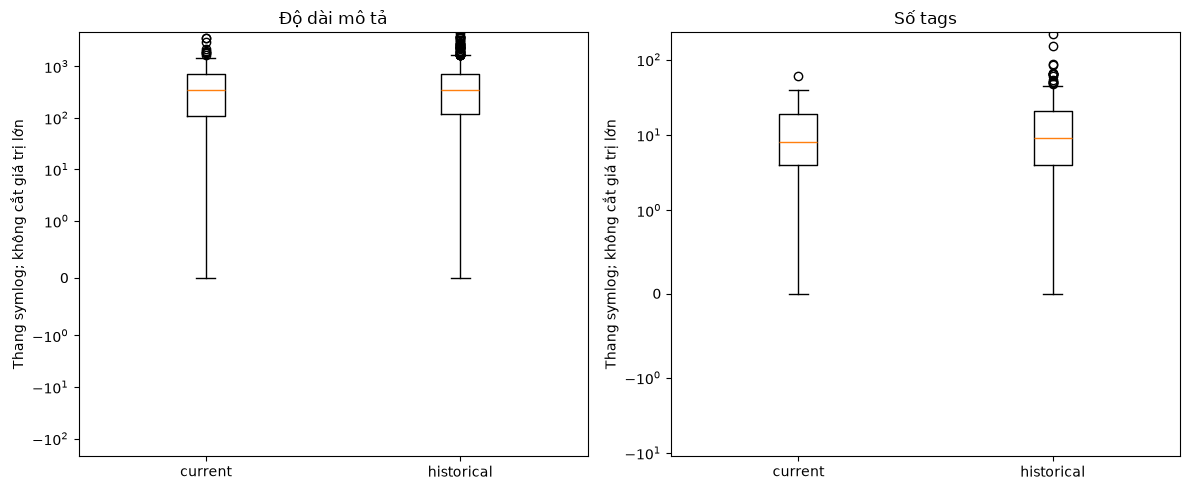

In [24]:
figure, axes = plt.subplots(1, 2, figsize=(12, 5))
origins = ["current", "historical"]
for axis, column, counter, title in [
    (axes[0], "description", text_length, "Độ dài mô tả"),
    (axes[1], "tags", tag_count, "Số tags"),
]:
    values = [video_metadata.loc[video_metadata["_source_origin"].eq(origin), column]
              .map(counter).dropna().to_numpy() for origin in origins]
    axis.boxplot(values, positions=[1, 2], showfliers=True)
    axis.set_xticks([1, 2], origins)
    axis.set_yscale("symlog", linthresh=1)
    axis.set_title(title)
    axis.set_ylabel("Thang symlog; không cắt giá trị lớn")
figure.tight_layout()
plt.show()


In [25]:
def inspect_metadata_links(frame, metadata, received_column):
    joined = frame.merge(
        metadata[["duration_seconds", "crawled_at", "upload_date"]],
        left_on="video_id", right_index=True, how="left",
        validate="many_to_one", indicator="_metadata_match",
    )
    if len(joined) != len(frame):
        raise ValueError("Phép nối làm thay đổi số dòng tương tác")
    duration = pd.to_numeric(joined["duration_seconds"], errors="coerce")
    watch = joined["watch_duration_seconds"]
    completion = joined["completion_rate"]
    comparable = duration.gt(0) & watch.notna() & completion.notna()
    difference = (completion - watch / duration).abs()
    crawled = pd.to_datetime(joined["crawled_at"], format="ISO8601", utc=True, errors="coerce")
    received = pd.to_datetime(joined[received_column], unit="ms", utc=True, errors="coerce")
    uploaded = pd.to_datetime(joined["upload_date"], format="%Y%m%d", utc=True, errors="coerce")
    summary = pd.Series({
        "Số sự kiện": len(joined),
        "Sự kiện không tìm thấy metadata": joined["_metadata_match"].eq("left_only").sum(),
        "Đủ trường để đối chiếu completion": comparable.sum(),
        "Completion lệch công thức trên 0,001": (comparable & difference.gt(0.001)).sum(),
        "Không đọc được thời điểm crawl": crawled.isna().sum(),
        "Không đọc được thời điểm server nhận": received.isna().sum(),
        "Metadata được crawl sau thời điểm server nhận": crawled.gt(received).sum(),
        "Ngày đăng thiếu hoặc không đọc được": uploaded.isna().sum(),
        "Ngày đăng sau ngày server nhận": uploaded.dt.normalize().gt(received.dt.normalize()).sum(),
    })
    joined["_completion_difference"] = difference
    joined["_completion_comparable"] = comparable
    joined["_metadata_after_receipt"] = crawled.gt(received)
    return joined, summary

gold_with_metadata, gold_link_summary = inspect_metadata_links(
    gold_eda, current_metadata, "server_received_timestamp_ms"
)
historical_with_metadata, historical_link_summary = inspect_metadata_links(
    historical_interactions, historical_metadata, "server_received_timestamp"
)
metadata_link_summary = pd.DataFrame({"Gold": gold_link_summary, "Lịch sử": historical_link_summary})
display(metadata_link_summary)

completion_mismatch_examples = historical_with_metadata.loc[
    historical_with_metadata["_completion_comparable"]
    & historical_with_metadata["_completion_difference"].gt(0.001),
    ["event_id", "user_id", "video_id", "watch_duration_seconds",
     "duration_seconds", "completion_rate", "_completion_difference", "app_version"],
].head(5)
print("Ví dụ lịch sử có completion không khớp công thức:")
display(completion_mismatch_examples)


,Gold,Lịch sử
Số sự kiện,28762,30796
Sự kiện không tìm thấy metadata,0,0
Đủ trường để đối chiếu completion,28215,29803
"Completion lệch công thức trên 0,001",0,487
Không đọc được thời điểm crawl,0,0
Không đọc được thời điểm server nhận,0,0
Metadata được crawl sau thời điểm server nhận,28762,30796
Ngày đăng thiếu hoặc không đọc được,311,762
Ngày đăng sau ngày server nhận,481,4703


Ví dụ lịch sử có completion không khớp công thức:


,event_id,user_id,video_id,watch_duration_seconds,duration_seconds,completion_rate,_completion_difference,app_version
38,evt_22fd52f587c9,usr_00598,maRokAuAINQ,19646.19,49.0,1309.75,908.807347,v3.12.0
59,evt_e00780057467,usr_00907,REuxYnRBs3k,27200.88,39.0,1813.39,1115.931538,v3.12.0
183,evt_5780855fa722,usr_00700,nbwweHCUtsA,22055.36,33.0,1470.36,802.015758,v3.12.0
282,evt_56eeb0688dd2,usr_00334,D6GzP3OiMFs,5285.78,56.0,352.39,258.001071,v3.12.0
353,evt_f6ed9a988741,usr_00716,wZH9JOUQtZE,10690.64,19.0,712.71,150.044737,v3.12.0


### Nhận xét đối chiếu và thời điểm metadata

Cả 28.762 sự kiện Gold và 30.796 dòng lịch sử đều tìm được metadata của đúng
nguồn; phép nối không nhân số dòng. Trong các dòng đủ trường, Gold không có
completion lệch watch/duration quá 0,001; lịch sử có 487 dòng lệch.
Con số này khác 491 dòng watch vượt 3.600 giây: đây là hai tiêu chí khác nhau,
không được đồng nhất hay cộng lại thành số dòng lỗi độc lập.

Toàn bộ metadata được crawl sau thời điểm server nhận ghi trong log.
481 sự kiện Gold và 4.703 dòng lịch sử còn có ngày đăng video sau ngày server nhận.
311 sự kiện Gold và 762 dòng lịch sử gắn với ngày đăng thiếu/không đọc được;
các số này đếm dòng tương tác, không phải số video.

Đây là dấu hiệu thời gian giả lập không khớp hoàn toàn với lịch sử tồn tại của video.
Không thể xem timestamp này là bằng chứng về một hệ thống thật dự đoán tương lai.
Không đưa view/like/comment count tại lúc crawl vào mô hình dự đoán tại thời điểm
log cũ. Nếu dùng metadata văn bản như một catalogue tĩnh thì phải công bố rõ
giao thức đó, thay vì tuyên bố metadata đã có sẵn ở thời điểm từng sự kiện.
EDA chỉ ghi nhận giới hạn, không sửa ngày hay dịch chuyển log để che bất nhất.


## 3. Phân bố tương tác, độ tập trung và biểu đồ

Bảng video và đường tích lũy dưới đây thống kê riêng từng run Gold và lịch sử thô.
Số video xuất hiện trong log không chứng minh toàn bộ tập ứng viên đã được phơi bày.
Tỷ lệ sự kiện tập trung ở video phổ biến không phải metric coverage của mô hình.
Lịch sử còn bot/bản lặp; không dùng so sánh thô này để kết luận nguồn nào có chất lượng mô hình tốt hơn.


,Số sự kiện,Video xuất hiện,Sự kiện ít nhất/video,Trung vị sự kiện/video,Sự kiện nhiều nhất/video,Tỷ lệ sự kiện ở 10 video đầu (%)
Nguồn,,,,,,
run=2ad86635f1a18e06,9631,76,70,92.0,1007,38.26
run=94f1d592a7787780,9184,42,137,171.0,1864,42.82
run=e1d06d3cf6587c44,9947,107,52,82.0,902,21.14
historical_raw,30796,491,31,56.0,599,11.79


Phân bố giá trị số: Gold


,count,mean,std,min,1%,25%,50%,75%,99%,max
watch_duration_seconds,28215.0,26.990937,27.004798,0.12,0.440,2.190,18.620,46.315,97.0558,107.95
completion_rate,28215.0,0.846121,0.636562,0.02,0.022,0.078,1.003,1.406,1.7830,1.80
comment_read_duration_seconds,28762.0,3.528318,6.892043,0.00,0.000,0.000,0.000,0.000,24.2439,24.99


Phân bố giá trị số: Lịch sử thô


,count,mean,std,min,1%,25%,50%,75%,99%,max
watch_duration_seconds,30307.0,286.830746,2227.122468,-1.000,-1.000,2.030,19.920,47.70,13065.0634,28787.54
completion_rate,29803.0,18.456317,149.810754,0.001,0.001,0.063,0.987,1.41,879.8730,1919.17
comment_read_duration_seconds,30796.0,3.439506,6.813507,0.000,0.000,0.000,0.000,0.00,24.1000,24.99


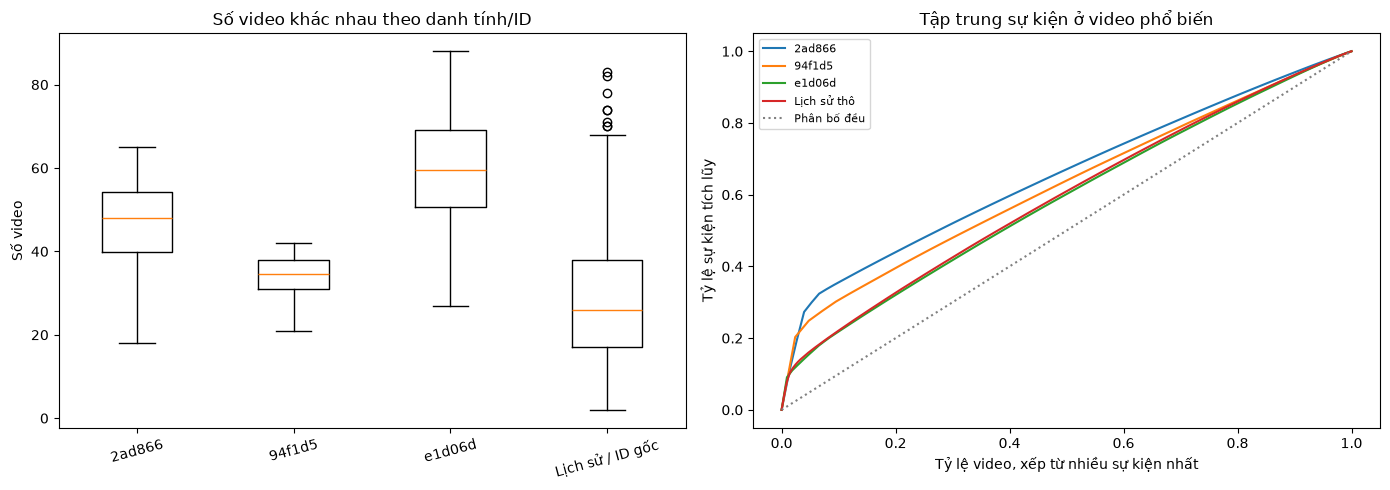

In [26]:
import numpy as np
import matplotlib.pyplot as plt

EDA_REPORT_DIR = REPORT_DIR / "eda_v1"
EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

analysis_groups = {
    run_name: group for run_name, group in gold_eda.groupby("_source_run")
}
analysis_groups["historical_raw"] = historical_interactions
video_count_series = {
    name: frame["video_id"].value_counts()
    for name, frame in analysis_groups.items()
}
activity_rows = []
for name, counts in video_count_series.items():
    sorted_counts = counts.sort_values(ascending=False)
    activity_rows.append({
        "Nguồn": name,
        "Số sự kiện": int(counts.sum()),
        "Video xuất hiện": len(counts),
        "Sự kiện ít nhất/video": int(counts.min()),
        "Trung vị sự kiện/video": float(counts.median()),
        "Sự kiện nhiều nhất/video": int(counts.max()),
        "Tỷ lệ sự kiện ở 10 video đầu (%)": float(sorted_counts.head(10).sum() / counts.sum() * 100),
    })
video_activity_summary = pd.DataFrame(activity_rows).set_index("Nguồn")
display(video_activity_summary.round(2))

for name, frame in {"Gold": gold_eda, "Lịch sử thô": historical_interactions}.items():
    print("Phân bố giá trị số:", name)
    display(frame[["watch_duration_seconds", "completion_rate", "comment_read_duration_seconds"]]
            .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
user_series = {
    name.removeprefix("run=")[:6]: group["distinct_video_count"]
    for name, group in user_activity.groupby(level="_source_run")
}
user_series["Lịch sử / ID gốc"] = historical_user_activity["distinct_video_count"]
positions = np.arange(1, len(user_series) + 1)
axes[0].boxplot(list(user_series.values()), positions=positions, showfliers=True)
axes[0].set_xticks(positions, list(user_series), rotation=15)
axes[0].set_title("Số video khác nhau theo danh tính/ID")
axes[0].set_ylabel("Số video")
for name, counts in video_count_series.items():
    ordered = counts.sort_values(ascending=False)
    x_values = np.arange(1, len(ordered) + 1) / len(ordered)
    label = name.removeprefix("run=")[:6] if name.startswith("run=") else "Lịch sử thô"
    axes[1].plot(np.r_[0, x_values], np.r_[0, ordered.cumsum().to_numpy() / ordered.sum()], label=label)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":", label="Phân bố đều")
axes[1].set_title("Tập trung sự kiện ở video phổ biến")
axes[1].set_xlabel("Tỷ lệ video, xếp từ nhiều sự kiện nhất")
axes[1].set_ylabel("Tỷ lệ sự kiện tích lũy")
axes[1].legend(fontsize=8)
figure.tight_layout()
figure.savefig(EDA_REPORT_DIR / "activity_distributions.png", dpi=130, bbox_inches="tight")
plt.show()


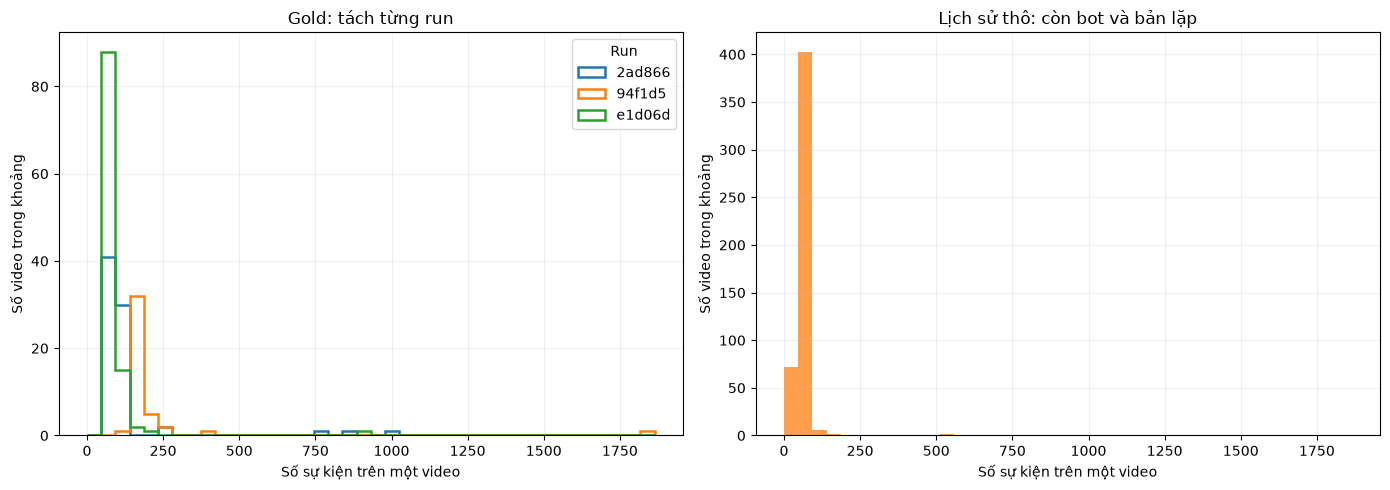

In [27]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
video_bins = np.linspace(0, max(counts.max() for counts in video_count_series.values()), 41)
for name, counts in video_count_series.items():
    if name.startswith("run="):
        axes[0].hist(counts, bins=video_bins, histtype="step", linewidth=1.8,
                     label=name.removeprefix("run=")[:6])
axes[1].hist(video_count_series["historical_raw"], bins=video_bins, color="tab:orange", alpha=0.75)
for axis, title in zip(axes, ["Gold: tách từng run", "Lịch sử thô: còn bot và bản lặp"]):
    axis.set_title(title)
    axis.set_xlabel("Số sự kiện trên một video")
    axis.set_ylabel("Số video trong khoảng")
    axis.grid(alpha=0.2)
axes[0].legend(title="Run")
figure.tight_layout()
plt.show()


### Nhận xét phân bố

10 video nhiều sự kiện nhất chiếm lần lượt 38,26%, 42,82% và 21,14% sự kiện
ở ba run Gold; trong lịch sử thô là 11,79%. Các catalogue quan sát có kích thước
khác nhau (76, 42, 107 và 491 video), nên tỷ lệ top-10 tuyệt đối không đủ để
kết luận nguồn nào tập trung hơn trên cùng quy mô. Đường tích lũy theo tỷ lệ video
cho thấy mỗi nguồn đều có nhóm video được tương tác nhiều hơn phần còn lại.
Đó là mức tập trung của log, chưa phải coverage hay chất lượng đề xuất.

Trung vị số video mỗi danh tính Gold là 48, 34,5 và 59,5; lịch sử có trung vị
26 video/chuỗi ID trên lát cắt không thiếu user và không phải bot.
Lát cắt này vẫn còn bản lặp và chưa xác minh danh tính xuyên lần sinh hồ sơ.
Độ dài lịch sử không đồng đều, khác pilot từng phân đều 210 video train/user.

Biểu đồ watch/completion giữ rõ các giá trị cực lớn trong lịch sử thô;
Gold đã được ETL lọc một số dạng nhiễu nhưng vẫn có thiếu do block và lệch đồng hồ.
Mô tả/tags có độ dài phân tán lớn, nên không mặc định văn bản dài hơn hữu ích hơn.

Biểu đồ dùng dropna chỉ để bỏ vị trí không thể vẽ; đầu vào vẫn giữ mọi dòng
và số thiếu được thống kê riêng. Thang symlog giữ cả số âm, 0 và outlier,
không cắt giá trị để biểu đồ trông sạch hơn.


## 4. Kết luận EDA và công việc dành cho preprocessing

**Đã hoàn tất EDA trong phạm vi nguồn hiện có. 

### Những gì đã xác nhận

Hai nguồn gồm 28.762 sự kiện Gold và 30.796 dòng lịch sử thô. Không cộng raw hiện tại
lần nữa vì chúng là đầu vào của các sự kiện Gold này. Metadata có 598 bản từ hai nguồn,
tương ứng 560 video_id; 38 video chung giống nhau ở năm trường đã đối chiếu.
Mọi sự kiện đều nối được metadata mà không làm tăng số dòng.

Gold có 300 danh tính theo cặp (run, user_id), không phải chỉ 100 hồ sơ xuyên ba run.
Lịch sử có 982 chuỗi ID không phải bot nhưng chưa xác minh được phạm vi lần sinh hồ sơ.
Vì vậy chưa có cơ sở khẳng định tổng số người dùng độc lập của hai nguồn là 1.282.
Hành vi của cả hai nguồn là giả lập; đây không phải nhật ký của người dùng thật.

Gold đã qua ETL nhưng chưa đủ để dùng nguyên trạng cho mô hình: vẫn có giá trị thiếu
đi cùng block, block giữ like/share, 550 sự kiện lệch đồng hồ khoảng hai ngày,
và metadata có bất nhất thời gian với log. Lịch sử còn thêm missing user, bot,
event ID lặp, watch âm và outlier. Dữ liệu có thể dùng phát triển và đánh giá nội bộ
với giới hạn được công bố; EDA chưa chứng minh mô hình sẽ tốt hoặc tổng quát hóa ngoài mô phỏng.


In [28]:
final_fingerprints = {
    "gold": frame_fingerprint(gold_interactions),
    "historical": frame_fingerprint(historical_interactions),
    "metadata": frame_fingerprint(video_metadata),
}
if final_fingerprints != input_fingerprints:
    raise ValueError("EDA đã làm thay đổi DataFrame đầu vào gốc")
if source_checksums(configuration["sources"]) != inspection_manifest["source_file_sha256"]:
    raise ValueError("File nguồn thay đổi trong lúc EDA")
if protected_file_checksums() != protected_before_eda:
    raise ValueError("Code/cấu hình collaborator thay đổi trong lúc EDA")

def table_as_records(table):
    return json.loads(table.to_json(orient="index", force_ascii=False, date_format="iso"))

eda_completion_summary = {
    "stage": "EDA_completed_not_preprocessing",
    "gold_events": len(gold_interactions),
    "historical_raw_events": len(historical_interactions),
    "metadata_records": len(video_metadata),
    "distinct_videos": int(video_metadata["video_id"].nunique()),
    "gold_scoped_user_count": int(scoped_user_count),
    "historical_nonbot_id_count_unverified": len(historical_user_activity),
    "negative_watch_matches_missing_completion": bool(negative_watch_matches_missing_completion),
    "metadata_overlap_count": len(common_video_ids),
    "metadata_field_differences": {name: int(count) for name, count in metadata_differences.sum().items()},
    "metadata_links": table_as_records(metadata_link_summary.T),
    "video_activity": table_as_records(video_activity_summary),
    "timestamp_delays": table_as_records(timestamp_delay_summary.T),
    "input_fingerprints": input_fingerprints,
    "input_dataframes_unchanged": final_fingerprints == input_fingerprints,
    "source_files_unchanged": True,
    "protected_files_unchanged": True,
    "historical_identity_resolved": False,
    "cleaning_applied": False,
    "features_created": False,
    "split_created": False,
    "training_performed": False,
}
for filename, table in {
    "metadata_links.csv": metadata_link_summary,
    "video_activity.csv": video_activity_summary,
    "metadata_quality.csv": metadata_quality_summary,
    "time_ranges.csv": pd.DataFrame.from_dict(time_ranges, orient="index"),
}.items():
    table.to_csv(EDA_REPORT_DIR / filename, encoding="utf-8-sig")
(EDA_REPORT_DIR / "summary.json").write_text(
    json.dumps(eda_completion_summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print("Đã hoàn tất các phép khảo sát EDA; đầu vào và code collaborator giữ nguyên.")
print("Bảng và biểu đồ mô tả:", EDA_REPORT_DIR)
print("Chưa làm sạch, tạo feature, chia tập hoặc huấn luyện.")


Đã hoàn tất các phép khảo sát EDA; đầu vào và code collaborator giữ nguyên.
Bảng và biểu đồ mô tả: C:\Users\Legion\Downloads\ThucHanh\recommendation\reports\eda_v1
Chưa làm sạch, tạo feature, chia tập hoặc huấn luyện.
